
# Exploratory Data Analysis of House Prices

## 1. Introduction

The main objective of this project is to perform Exploratory Data Analysis (EDA) on the Ames Housing Dataset.

The dataset contains information about houses, including their sale prices, quality, area, location, year built and other features.

### Objectives
- Understand the house price dataset.
- Identify numerical and categorical variables.
- Calculate descriptive statistics.
- Visualize data distributions.
- Study correlations between features and sale prices.
- Detect outliers.
- Handle missing values.
- Create a final EDA dashboard.

### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SciPy

### Dataset
Ames Housing Dataset – train.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df = pd.read_csv('/content/train.csv')

print("Dataset loaded successfully!")

print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Columns with missing values:")
print(missing)

print("\nTotal columns with missing values:", len(missing))

Columns with missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

Total columns with missing values: 19


## 2. Classification of Variables

In this section, we classify the dataset columns into numerical, categorical and ordinal variables.

In [ ]:
# Numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Categorical columns
categorical_cols = df.select_dtypes(include='object').columns.tolist()

# Ordinal columns
ordinal_cols = ['OverallQual', 'ExterQual', 'KitchenQual']

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("Ordinal columns:", ordinal_cols)

Numerical columns: 38
Categorical columns: 43
Ordinal columns: ['OverallQual', 'ExterQual', 'KitchenQual']


In [ ]:
summary = []

for col in df.columns:
    if col in ordinal_cols:
        var_type = "Ordinal"
    elif col in numeric_cols:
        var_type = "Numerical"
    else:
        var_type = "Categorical"

    summary.append({
        'Column': col,
        'Type': var_type,
        'Unique Values': df[col].nunique(),
        'Examples': df[col].dropna().unique()[:5].tolist()
    })

variable_summary = pd.DataFrame(summary)

variable_summary.head(20)

,Column,Type,Unique Values,Examples
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
5,Street,Categorical,2,"[Pave, Grvl]"
6,Alley,Categorical,2,"[Grvl, Pave]"
7,LotShape,Categorical,4,"[Reg, IR1, IR2, IR3]"
8,LandContour,Categorical,4,"[Lvl, Bnk, Low, HLS]"
9,Utilities,Categorical,2,"[AllPub, NoSeWa]"


In [ ]:
quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']

for col in ['ExterQual', 'KitchenQual']:
    df[col] = pd.Categorical(
        df[col],
        categories=quality_order,
        ordered=True
    )

print("Ordinal variables classified successfully!")

Ordinal variables classified successfully!


## 3. Descriptive Statistics

Descriptive statistics help us understand the central tendency and spread of house prices and other numerical features.

In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:
    print("\nStatistics for:", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())
    print("IQR:", df[col].quantile(0.75) - df[col].quantile(0.25))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurtosis())

    if df[col].mean() > df[col].median():
        print("Distribution: Right Skewed")
    elif df[col].mean() < df[col].median():
        print("Distribution: Left Skewed")
    else:
        print("Distribution: Approximately Symmetrical")


Statistics for: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529
Distribution: Right Skewed

Statistics for: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174
Distribution: Right Skewed

Statistics for: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033
Distribution: Right Skewed


In [ ]:
for col in ['Neighborhood', 'HouseStyle']:
    print("\nValue counts for:", col)
    print(df[col].value_counts())

    print("Mode:", df[col].mode()[0])


Value counts for: Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64
Mode: NAmes

Value counts for: HouseStyle
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64
Mode: 1Story


## 4. Distribution Analysis

In this section, we visualize house prices using histograms, KDE plots and boxplots. We also compare the original and logarithmic distributions.

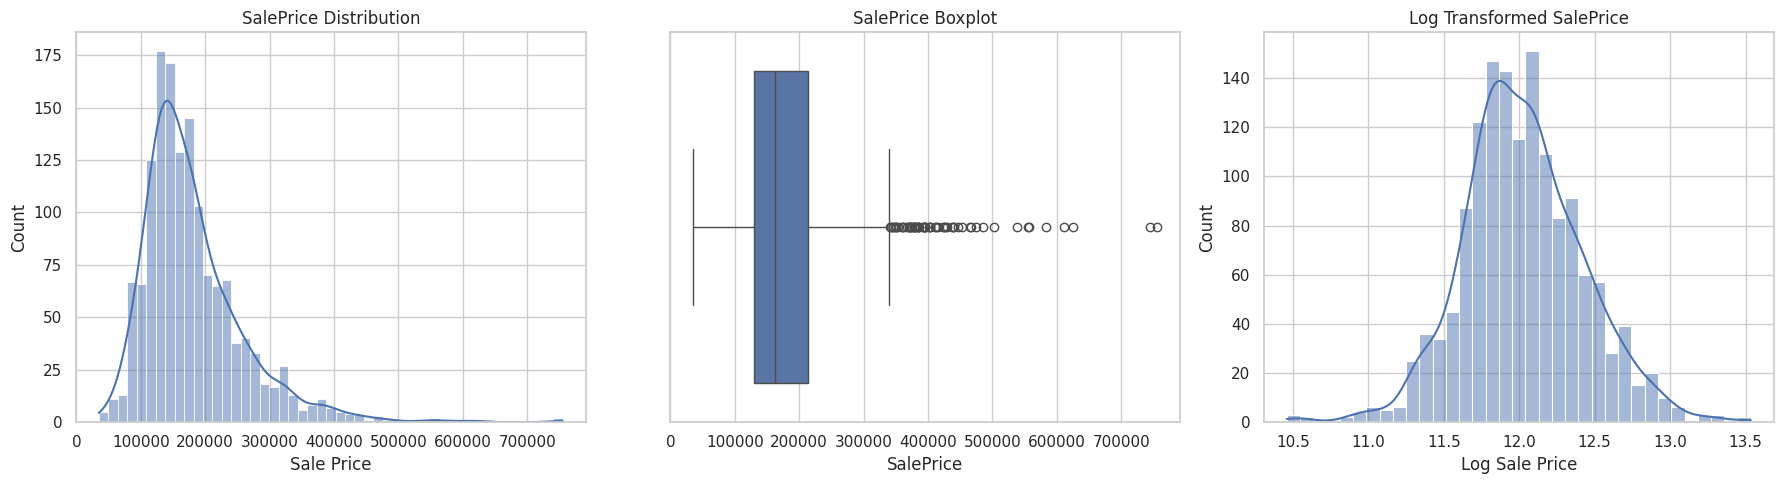

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram with KDE
sns.histplot(df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('SalePrice Distribution')
axes[0].set_xlabel('Sale Price')

# Boxplot
sns.boxplot(x=df['SalePrice'], ax=axes[1])
axes[1].set_title('SalePrice Boxplot')

# Log histogram
sns.histplot(np.log1p(df['SalePrice']), kde=True, ax=axes[2])
axes[2].set_title('Log Transformed SalePrice')
axes[2].set_xlabel('Log Sale Price')

plt.tight_layout()
plt.show()

In [ ]:
print("Original skewness:", df['SalePrice'].skew())

log_price = np.log1p(df['SalePrice'])

print("Log transformed skewness:", log_price.skew())

Original skewness: 1.8828757597682129
Log transformed skewness: 0.12134661989685333


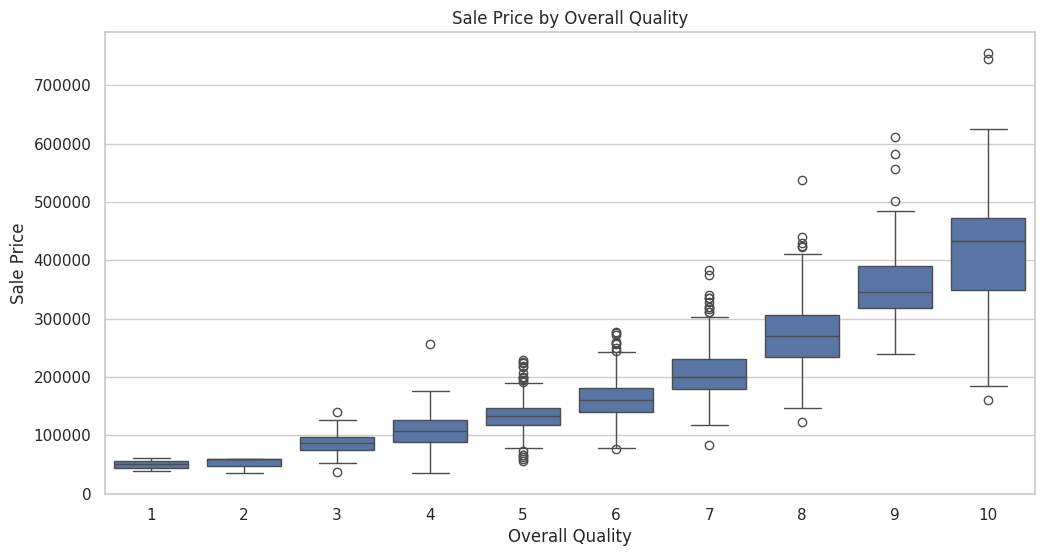

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(x='OverallQual', y='SalePrice', data=df)

plt.title('Sale Price by Overall Quality')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()

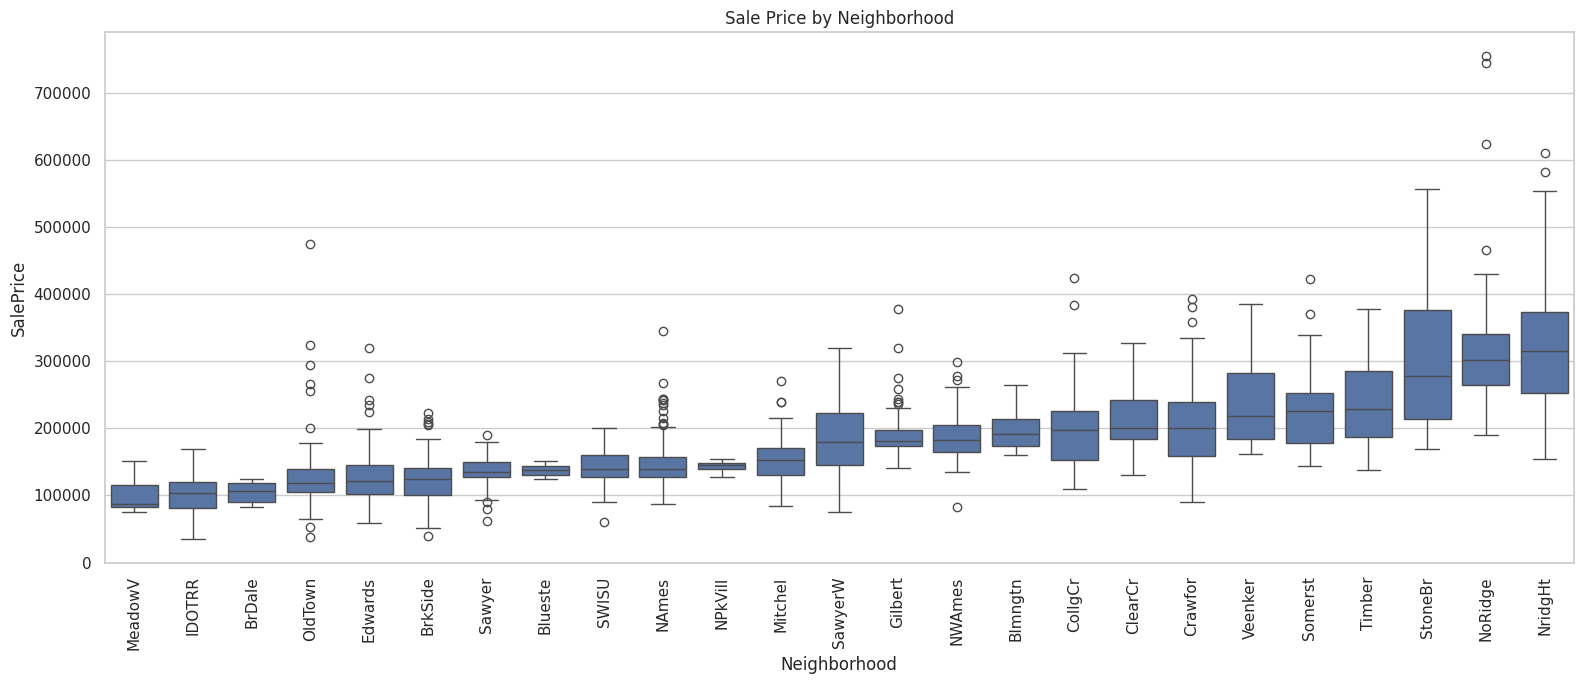

In [ ]:
neighborhood_order = (
    df.groupby('Neighborhood', observed=True)['SalePrice']
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(16, 7))

sns.boxplot(
    x='Neighborhood',
    y='SalePrice',
    data=df,
    order=neighborhood_order
)

plt.title('Sale Price by Neighborhood')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

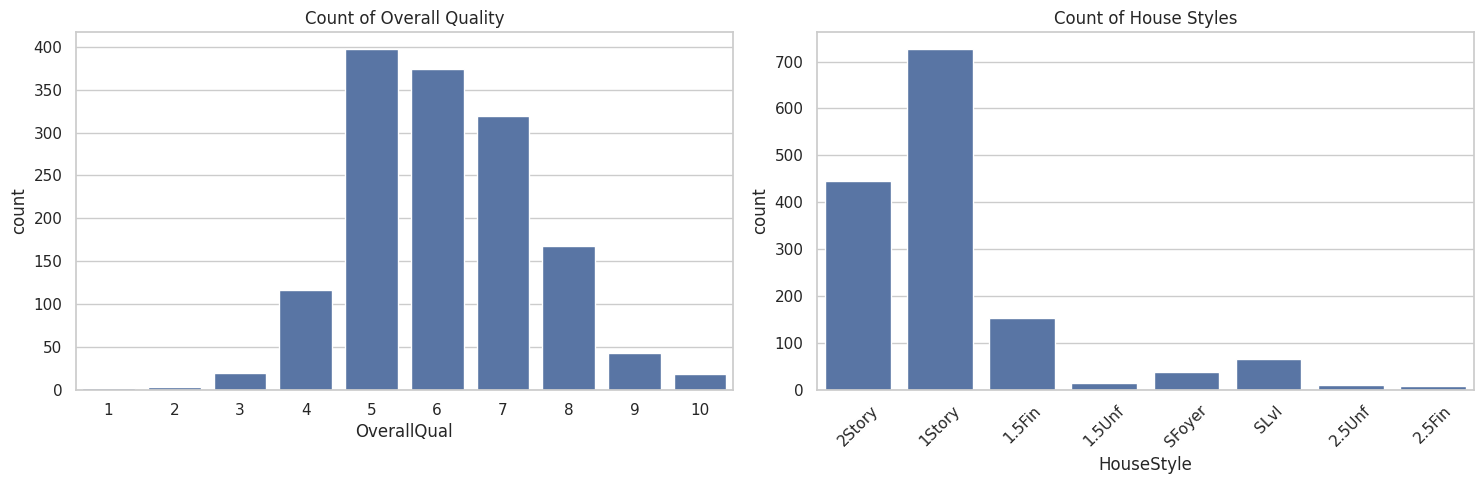

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(x='OverallQual', data=df, ax=axes[0])
axes[0].set_title('Count of Overall Quality')

sns.countplot(x='HouseStyle', data=df, ax=axes[1])
axes[1].set_title('Count of House Styles')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 5. Correlation and Covariance

Correlation measures the strength and direction of the relationship between two numerical variables. Covariance indicates how two variables change together.

In [ ]:
# Correlation matrix
corr_matrix = df.select_dtypes(include=np.number).corr()

# Covariance matrix
cov_matrix = df.select_dtypes(include=np.number).cov()

print("Correlation Matrix:")
display(corr_matrix.head())

print("Covariance Matrix:")
display(cov_matrix.head())

Correlation Matrix:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982


Covariance Matrix:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,177755.000000,198.968472,-108.390207,-1.398197e+05,-16.539068,5.915696,-161.881768,-191.474297,-3842.687941,-966.102125,...,-1566.467786,-13.322138,74.450651,-576.428376,31.270391,966.275531,-1305.726525,24.133653,0.398561,-7.340732e+05
MSSubClass,198.968472,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,35.581337,35.439934,175.837842,-1347.355751,...,-66.694532,-17.096613,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-108.390207,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,95.108483,45.744675,871.207424,2635.952669,...,258.788887,243.868123,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05
LotArea,-139819.667238,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4289.113242,2841.343594,188401.408828,974690.774209,...,214800.625342,56062.527573,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,-16.539068,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,23.906215,15.723417,103.012054,151.176998,...,41.415726,28.297642,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04


In [ ]:
top_corr = (
    corr_matrix['SalePrice']
    .drop('SalePrice')
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 features correlated with SalePrice:")
display(top_corr)

Top 10 features correlated with SalePrice:


,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [ ]:
top_features = corr_matrix['SalePrice'].drop('SalePrice').abs().nlargest(10).index

display(corr_matrix.loc[top_features, ['SalePrice']])

,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [ ]:
top3 = top_corr.head(3).index

for col in top3:
    print("\nFeature:", col)
    print("Correlation:", corr_matrix.loc[col, 'SalePrice'])
    print("Covariance:", cov_matrix.loc[col, 'SalePrice'])


Feature: OverallQual
Correlation: 0.7909816005838053
Covariance: 86904.12583679946

Feature: GrLivArea
Correlation: 0.7086244776126515
Covariance: 29581866.743236575

Feature: GarageCars
Correlation: 0.6404091972583519
Covariance: 38020.18135897172


## 6. Scatter Plots and Pair Plots

Scatter plots help us understand the relationship between two numerical variables and identify unusual observations.

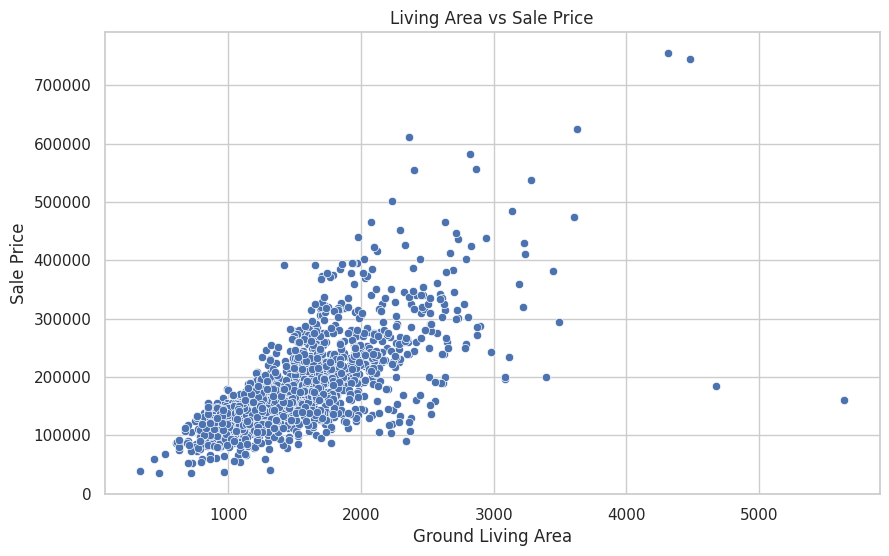

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='GrLivArea',
    y='SalePrice',
    data=df
)

plt.title('Living Area vs Sale Price')
plt.xlabel('Ground Living Area')
plt.ylabel('Sale Price')

plt.show()

In [ ]:
unusual = df[
    (df['GrLivArea'] > 4000) &
    (df['SalePrice'] < 200000)
]

print("Unusual observations:")
display(unusual[['GrLivArea', 'SalePrice', 'OverallQual']])

Unusual observations:


,GrLivArea,SalePrice,OverallQual
523,4676,184750,10
1298,5642,160000,10


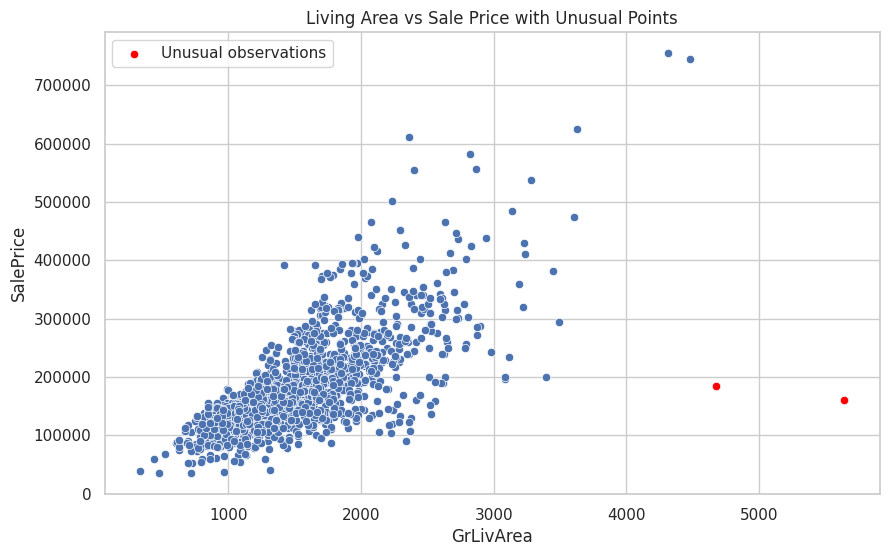

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice'
)

sns.scatterplot(
    data=unusual,
    x='GrLivArea',
    y='SalePrice',
    color='red',
    label='Unusual observations'
)

plt.title('Living Area vs Sale Price with Unusual Points')
plt.legend()
plt.show()

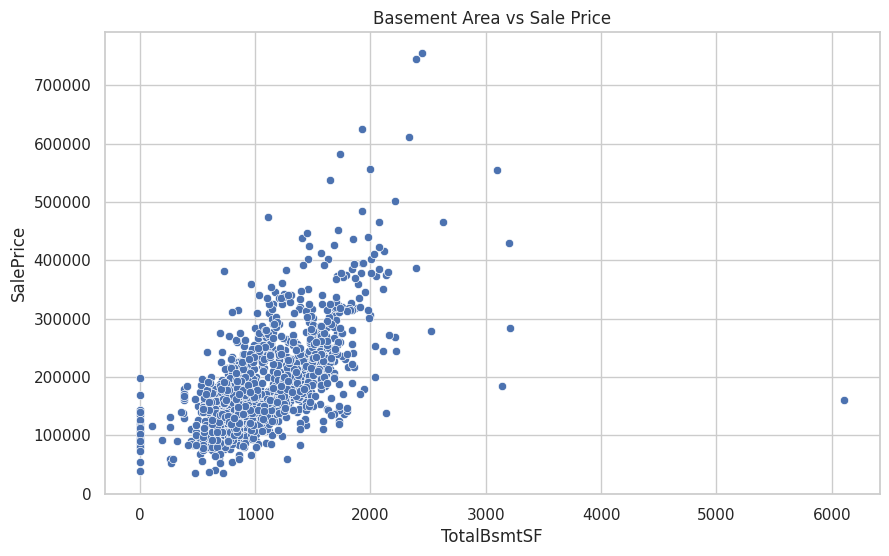

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x='TotalBsmtSF', y='SalePrice', data=df)

plt.title('Basement Area vs Sale Price')
plt.show()

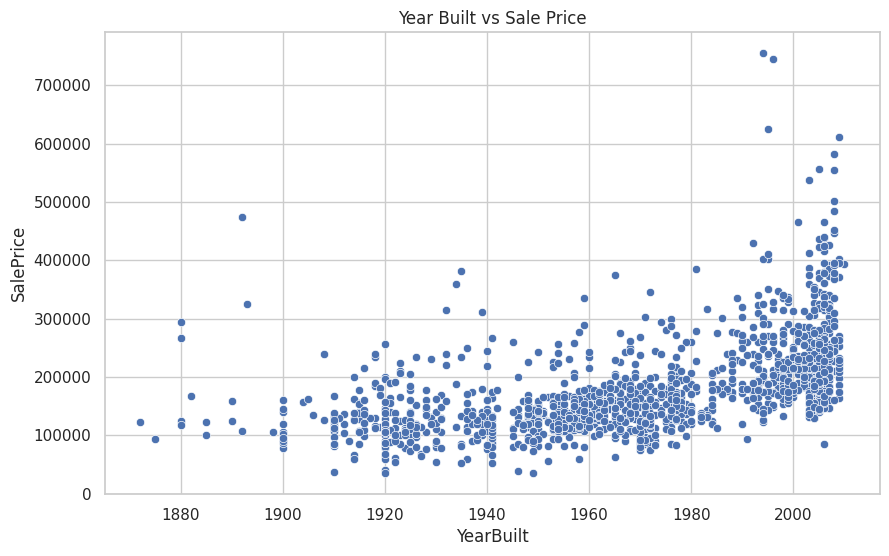

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x='YearBuilt', y='SalePrice', data=df)

plt.title('Year Built vs Sale Price')
plt.show()

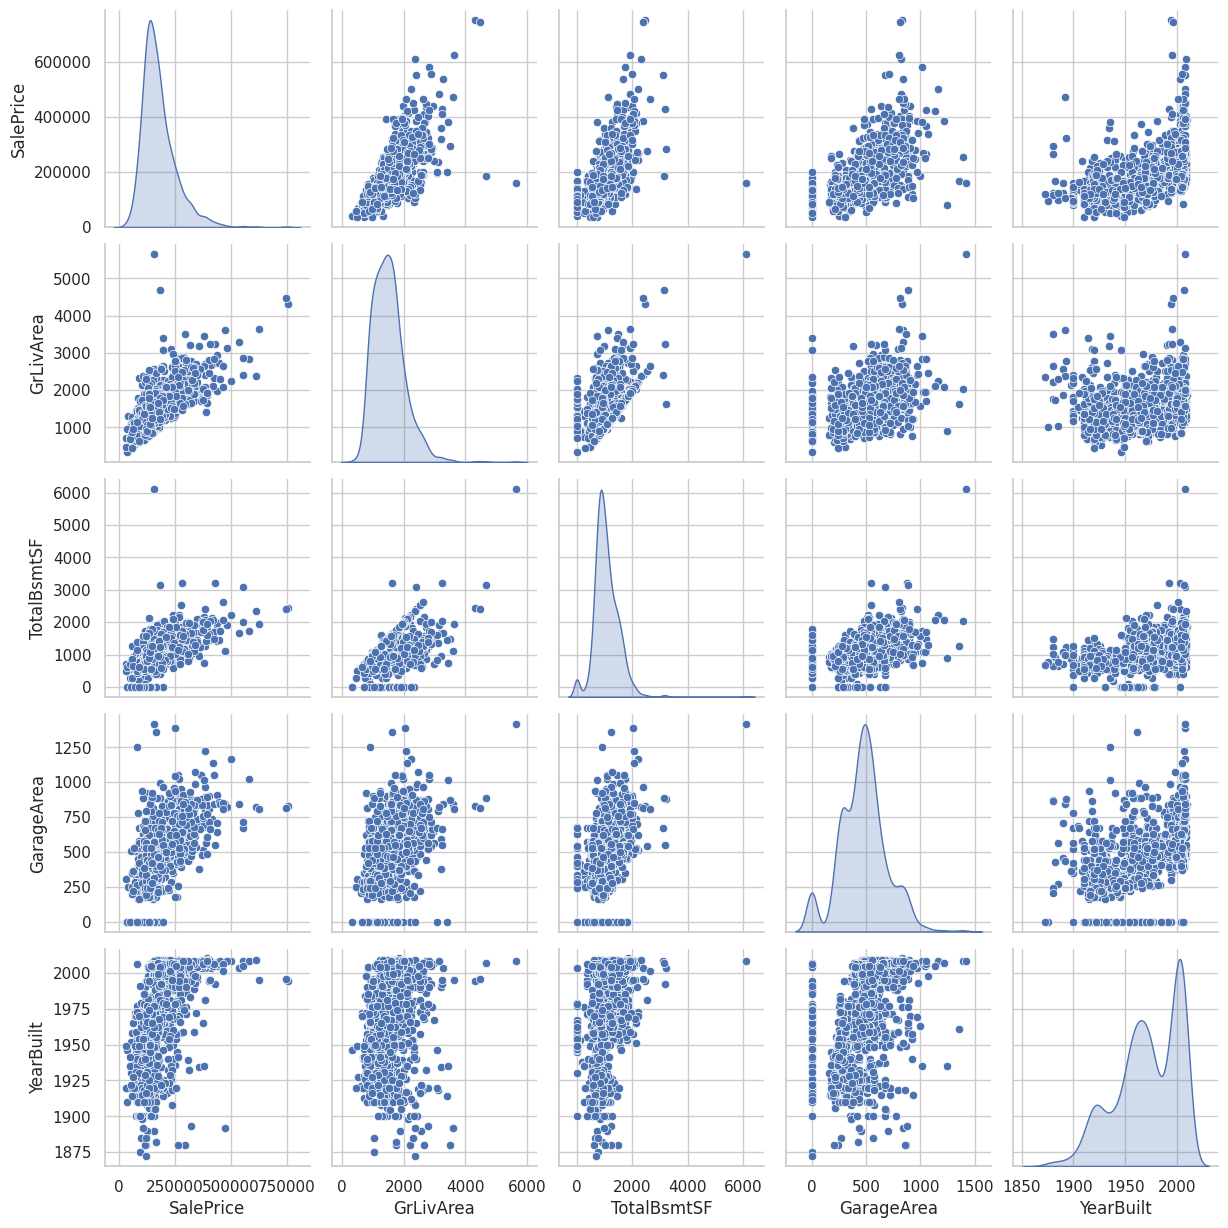

In [ ]:
selected = [
    'SalePrice',
    'GrLivArea',
    'TotalBsmtSF',
    'GarageArea',
    'YearBuilt'
]

sns.pairplot(df[selected], diag_kind='kde')

plt.show()

## 7. Correlation Heatmap

A correlation heatmap visually represents the relationships between numerical features. It helps identify the features most strongly related to SalePrice.

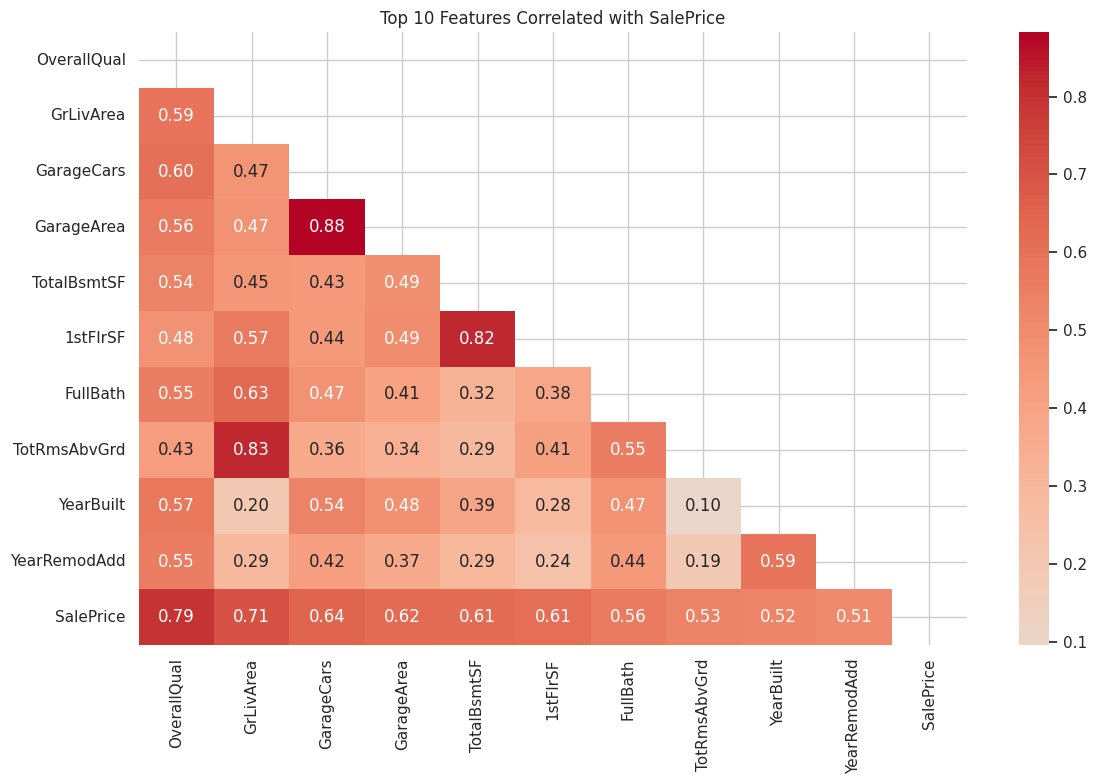

In [ ]:
top10 = (
    corr_matrix['SalePrice']
    .drop('SalePrice')
    .abs()
    .nlargest(10)
    .index
)

corr_top = df[top10.tolist() + ['SalePrice']].corr()

mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_top,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    mask=mask
)

plt.title('Top 10 Features Correlated with SalePrice')
plt.tight_layout()
plt.show()

## 8. Outlier Detection

Outliers are observations that are unusually high or low compared to other observations. In this project, we use IQR and Z-score methods to detect outliers.

In [ ]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return series[(series < lower) | (series > upper)]

In [ ]:
def zscore_outliers(series, threshold=3):
    z = np.abs(stats.zscore(series, nan_policy='omit'))

    return series[z > threshold]

In [ ]:
for col in ['GrLivArea', 'SalePrice']:

    iqr_result = iqr_outliers(df[col])
    zscore_result = zscore_outliers(df[col])

    print("\nColumn:", col)
    print("IQR outliers:", len(iqr_result))
    print("Z-score outliers:", len(zscore_result))

    overlap = set(iqr_result.index).intersection(
        set(zscore_result.index)
    )

    print("Common outliers:", len(overlap))


Column: GrLivArea
IQR outliers: 31
Z-score outliers: 16
Common outliers: 16

Column: SalePrice
IQR outliers: 61
Z-score outliers: 22
Common outliers: 22


In [ ]:
def zscore_outliers(series, threshold=3):
    z = np.abs(stats.zscore(series, nan_policy='omit'))

    return series[z > threshold]

In [ ]:
for col in ['GrLivArea', 'SalePrice']:

    iqr_result = iqr_outliers(df[col])
    zscore_result = zscore_outliers(df[col])

    print("\nColumn:", col)
    print("IQR outliers:", len(iqr_result))
    print("Z-score outliers:", len(zscore_result))

    overlap = set(iqr_result.index).intersection(
        set(zscore_result.index)
    )

    print("Common outliers:", len(overlap))


Column: GrLivArea
IQR outliers: 31
Z-score outliers: 16
Common outliers: 16

Column: SalePrice
IQR outliers: 61
Z-score outliers: 22
Common outliers: 22


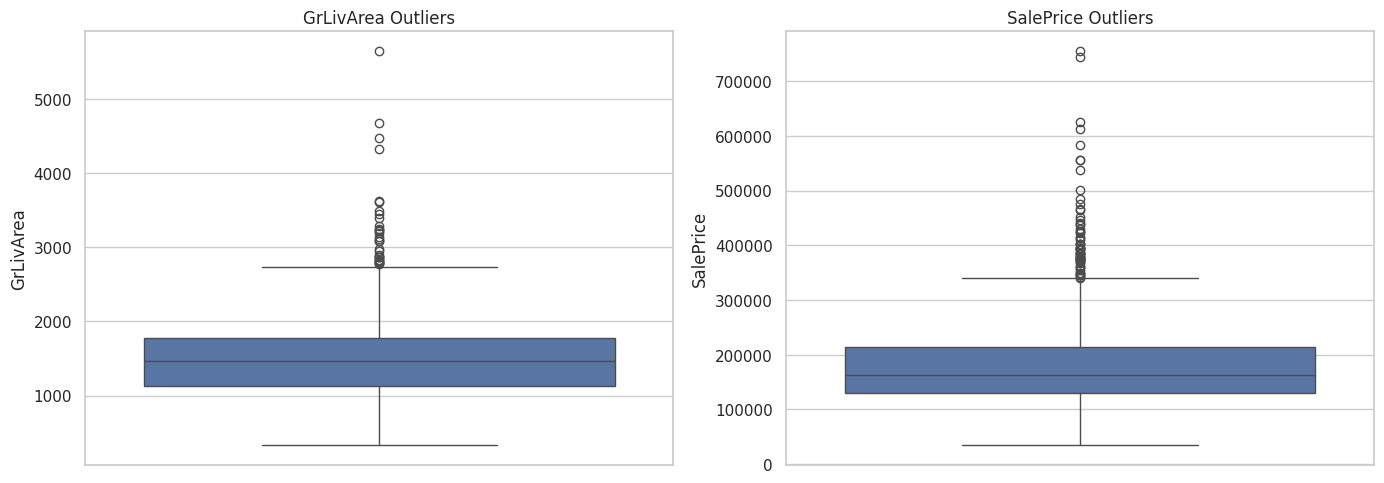

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df['GrLivArea'], ax=axes[0])
axes[0].set_title('GrLivArea Outliers')

sns.boxplot(y=df['SalePrice'], ax=axes[1])
axes[1].set_title('SalePrice Outliers')

plt.tight_layout()
plt.show()

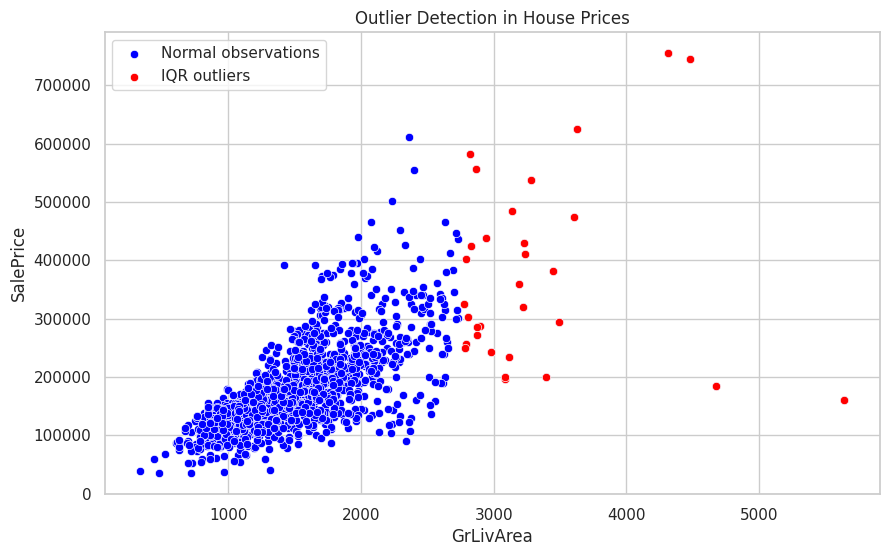

In [ ]:
outlier_indices = iqr_outliers(df['GrLivArea']).index

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice',
    color='blue',
    label='Normal observations'
)

sns.scatterplot(
    data=df.loc[outlier_indices],
    x='GrLivArea',
    y='SalePrice',
    color='red',
    label='IQR outliers'
)

plt.title('Outlier Detection in House Prices')
plt.legend()
plt.show()

## 9. Data Quality Checks and Cleaning

In this section, we check duplicate rows, inconsistent categorical values and missing values. We also check for impossible values.

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (1460, 81)


In [ ]:
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].dropna().unique()[:20])


Column: MSZoning
['RL' 'RM' 'C (all)' 'FV' 'RH']

Column: Street
['Pave' 'Grvl']

Column: Alley
['Grvl' 'Pave']

Column: LotShape
['Reg' 'IR1' 'IR2' 'IR3']

Column: LandContour
['Lvl' 'Bnk' 'Low' 'HLS']

Column: Utilities
['AllPub' 'NoSeWa']

Column: LotConfig
['Inside' 'FR2' 'Corner' 'CulDSac' 'FR3']

Column: LandSlope
['Gtl' 'Mod' 'Sev']

Column: Neighborhood
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr']

Column: Condition1
['Norm' 'Feedr' 'PosN' 'Artery' 'RRAe' 'RRNn' 'RRAn' 'PosA' 'RRNe']

Column: Condition2
['Norm' 'Artery' 'RRNn' 'Feedr' 'PosN' 'PosA' 'RRAn' 'RRAe']

Column: BldgType
['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']

Column: HouseStyle
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']

Column: RoofStyle
['Gable' 'Hip' 'Gambrel' 'Mansard' 'Flat' 'Shed']

Column: RoofMatl
['CompShg' 'WdShngl' 'Metal

In [ ]:
for col in categorical_cols:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Categorical values checked.")

Categorical values checked.


In [ ]:
absence_cols = [
    'PoolQC',
    'Alley',
    'Fence',
    'FireplaceQu',
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'MasVnrType'
]

for col in absence_cols:
    if col in df.columns:
        df[col] = df[col].fillna('None')

print("Feature absence values handled.")

Feature absence values handled.


In [ ]:
zero_cols = [
    'GarageYrBlt',
    'GarageArea',
    'GarageCars',
    'BsmtFinSF1',
    'BsmtFinSF2',
    'BsmtUnfSF',
    'TotalBsmtSF',
    'BsmtFullBath',
    'BsmtHalfBath',
    'MasVnrArea'
]

for col in zero_cols:
    if col in df.columns:
        df[col] = df[col].fillna(0)

In [ ]:
df['LotFrontage'] = df.groupby(
    'Neighborhood'
)['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

df['LotFrontage'] = df['LotFrontage'].fillna(
    df['LotFrontage'].median()
)

In [ ]:
for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
for col in df.select_dtypes(include=np.number).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

In [ ]:
print("Remaining missing values:")

print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Remaining missing values:
Series([], dtype: int64)

Total missing values: 0


In [ ]:
print(
    "YearBuilt greater than YrSold:",
    (df['YearBuilt'] > df['YrSold']).sum()
)

print(
    "Negative living area:",
    (df['GrLivArea'] < 0).sum()
)

print(
    "Negative lot area:",
    (df['LotArea'] < 0).sum()
)

YearBuilt greater than YrSold: 0
Negative living area: 0
Negative lot area: 0


In [ ]:
print(
    "YearBuilt greater than YrSold:",
    (df['YearBuilt'] > df['YrSold']).sum()
)

print(
    "Negative living area:",
    (df['GrLivArea'] < 0).sum()
)

print(
    "Negative lot area:",
    (df['LotArea'] < 0).sum()
)

YearBuilt greater than YrSold: 0
Negative living area: 0
Negative lot area: 0


## 10. Final Dashboard and Storytelling

The final dashboard combines four important visualizations to summarize the findings of the house price analysis.

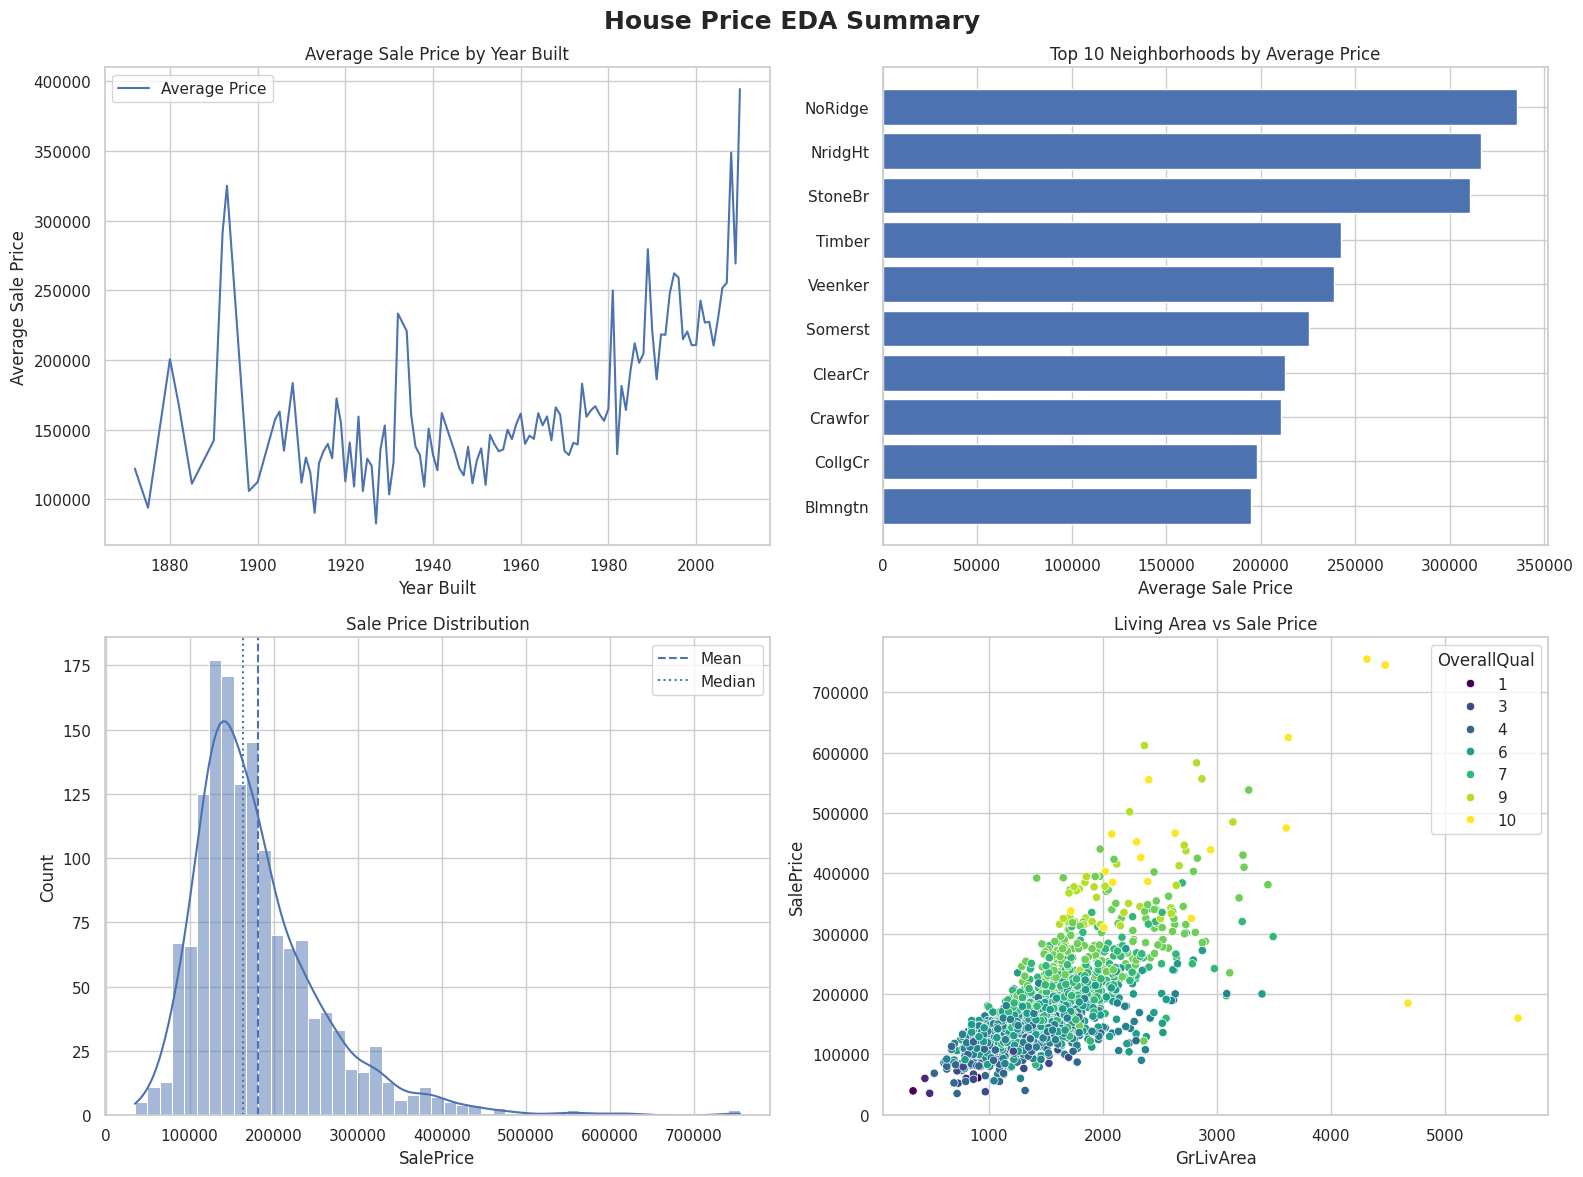

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: Average sale price by year built
year_price = df.groupby('YearBuilt')['SalePrice'].mean()

axes[0, 0].plot(
    year_price.index,
    year_price.values,
    label='Average Price'
)

axes[0, 0].set_title('Average Sale Price by Year Built')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Average Sale Price')
axes[0, 0].legend()


# Panel 2: Top 10 neighborhoods
neighborhood_price = (
    df.groupby('Neighborhood')['SalePrice']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

axes[0, 1].barh(
    neighborhood_price.index,
    neighborhood_price.values
)

axes[0, 1].set_title('Top 10 Neighborhoods by Average Price')
axes[0, 1].set_xlabel('Average Sale Price')
axes[0, 1].invert_yaxis()


# Panel 3: Sale price distribution
sns.histplot(
    df['SalePrice'],
    kde=True,
    ax=axes[1, 0]
)

axes[1, 0].axvline(
    df['SalePrice'].mean(),
    linestyle='--',
    label='Mean'
)

axes[1, 0].axvline(
    df['SalePrice'].median(),
    linestyle=':',
    label='Median'
)

axes[1, 0].set_title('Sale Price Distribution')
axes[1, 0].legend()


# Panel 4: Living area vs sale price
sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice',
    hue='OverallQual',
    palette='viridis',
    ax=axes[1, 1]
)

axes[1, 1].set_title('Living Area vs Sale Price')


plt.suptitle(
    'House Price EDA Summary',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    'eda_dashboard.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# 11. Conclusion

The Exploratory Data Analysis of the Ames Housing Dataset helped us understand the different factors associated with house sale prices.

### Key Findings

1. SalePrice distribution was examined using histograms and KDE plots.
2. Numerical features were compared using correlation and covariance.
3. OverallQual was analyzed to understand its relationship with house prices.
4. Neighborhoods were compared based on their average and median sale prices.
5. Outliers were detected using IQR and Z-score methods.
6. Missing values and duplicate records were checked and handled.
7. A final dashboard was created to summarize the analysis.

### Learning Outcomes

Through this project, we learned how to use Python, Pandas, NumPy, Matplotlib and Seaborn for Exploratory Data Analysis.

We also learned how to clean datasets, calculate descriptive statistics, visualize distributions, identify correlations and detect outliers.

### Final Result

The project demonstrates a complete Exploratory Data Analysis workflow without using machine learning.


In [ ]:
from google.colab import files

files.download('eda_dashboard.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>